# 信号処理 ― signal モジュール

## この章で学ぶこと

`signal` モジュールには、信号を整える処理、フィルタの設計、システムの応答を計算する関数があります。この章では、次の内容を例で確かめます。

* メディアンフィルタと順序フィルタでノイズを除く
* IIR フィルタを設計し、周波数応答を確かめる
* 周波数スイープ波で、フィルタの特性を測る
* 連続時間の線形システムを `lti` で表し、応答を計算する
* 伝達関数の計算で、PI 制御と PID 制御を組み立てる

In [1]:
from matplotlib import pyplot as plt

import helper.matplotlib
import numpy as np
from scipy import signal

## メディアンフィルタ

メディアンフィルタは、音声の瞬間的なノイズや、画像のごま塩ノイズを除くのに使います。`signal.medfilt()` は 1 次元の信号に、`signal.medfilt2d()` は 2 次元の信号に適用します。多次元の画像には `scipy.ndimage` のメディアンフィルタもあります。ここでは `medfilt()` の働きを見ます。

True


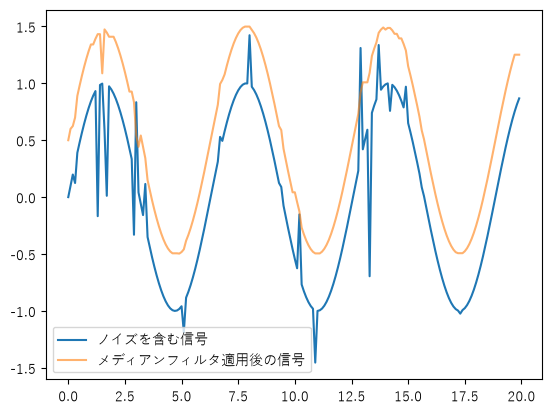

In [2]:
t = np.arange(0, 20, 0.1)
x = np.sin(t)
x[np.random.randint(0, len(t), 20)] += np.random.standard_normal(20) * 0.6  #❶ 瞬間的なノイズ
x2 = signal.medfilt(x, 5)  #❷ 窓の幅 5 のメディアンフィルタ
x3 = signal.order_filter(x, np.ones(5), 2)   # 順序フィルタでも同じ結果
print(np.all(x2 == x3))
plt.plot(t, x, label="ノイズを含む信号")
plt.plot(t, x2 + 0.5, alpha=0.6, label="メディアンフィルタ適用後の信号")
plt.legend(loc="best")
plt.show()

❶ 正弦波に、ランダムな位置の瞬間的なノイズを加えます。❷ `medfilt()` でメディアンフィルタをかけます。第 2 引数は中央値を求める窓の幅で、奇数である必要があります。`medfilt()` は各点を、その窓の中の中央値に置き換えます。

最後に、元の信号とフィルタをかけた信号を描きます。比べやすいように、フィルタ後の信号を 0.5 だけ上にずらしています。図から、とがったノイズだけが消えていることが分かります。

メディアンフィルタは、順序フィルタの特別な場合です。順序フィルタは、窓の中の値を小さい順に並べ、指定した順位の値に置き換えます。呼び方は次のとおりです。

```text
order_filter(a, domain, rank)
```

`a` は多次元配列、`domain` は窓の形を決める配列、`rank` は並べたときの順位で、0 が最小値、1 が 2 番目に小さい値になります。窓の幅が 5 なら、`rank=2` が中央値なので、`medfilt(x, 5)` と同じ結果になります。

## IIRフィルタの設計

`signal` モジュールには、フィルタを設計する関数がたくさんあります。ここでは IIR のバンドパスフィルタを設計し、周波数応答を確かめ、最後に周波数スイープ波をフィルタに通します。

In [3]:
sampling_rate = 8000.0

# バンドパスフィルタを設計する
# 通過域は 0.2*4000 〜 0.5*4000、阻止域は 0.1*4000 未満と 0.6*4000 より上
# 通過域のリップルは 2dB、阻止域の減衰は 40dB
b, a = signal.iirdesign([0.2, 0.5], [0.1, 0.6], 2, 40)  #❶

w, h = signal.freqz(b, a)                                  #❷ 周波数応答

power = 20 * np.log10(np.clip(np.abs(h), 1e-8, 1e100))     #❸ ゲイン(dB)
freq = w / np.pi * sampling_rate / 2                       #❹ 周波数(Hz)

❶ `iirdesign()` で IIR のバンドパスフィルタを設計します。通過域は $0.2 f_0$ から $0.5 f_0$、阻止域は $0.1 f_0$ より下と $0.6 f_0$ より上です。$f_0$ はサンプリング周波数の半分で、8kHz のサンプリングなら $f_0=4$kHz です。つまり、通過域は 800Hz から 2kHz になります。通過域のリップルは 2dB、阻止域の減衰は 40dB 以上です。

`iirdesign()` は、IIR フィルタの分子と分母の係数 `b` と `a` を返します。`a[0]` は常に 1 です。

❷ `freqz()` で、フィルタの周波数応答を計算します。戻り値は `w` と `h` の 2 つです。`w` は円周波数で、$\omega f_0/\pi$ で実際の周波数になります。`h` は各周波数での応答で、複素数です。絶対値がゲイン特性、偏角が位相特性を表します。

❸ `h` の絶対値からゲインを dB で計算します。`h` には 0 に近い値が入るので、先に `clip()` で下限を付けてから対数関数を呼びます。❹ 周波数を Hz に直して、ゲイン特性を描きます。

実際の系では、周波数スイープ波を入力して出力を見ることで、その系の周波数特性を測ることがあります。次のコードは、その手順をシミュレーションします。

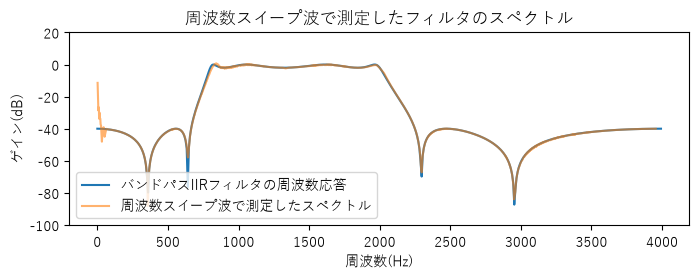

In [4]:
# 8kHz で 2 秒間の周波数スイープ波を作る。0Hz から sampling_rate/2 まで上げる
t_sweep = np.arange(0, 2, 1 / sampling_rate)                   #❶
sweep = signal.chirp(t_sweep, f0=0, t1=2, f1=sampling_rate / 2)  #❷
out = signal.lfilter(b, a, sweep)                              #❸ フィルタに通す
out_db = 20 * np.log10(np.abs(out))                            #❹ 振幅を dB にする
index = signal.argrelmax(out_db, order=3)                      #❺ 局所最大値

plt.figure(figsize=(8, 2.5))
plt.plot(freq, power, label="バンドパスIIRフィルタの周波数応答")
plt.plot(
    t_sweep[index] / 2.0 * 4000,
    out_db[index],
    label="周波数スイープ波で測定したスペクトル",
    alpha=0.6,
)  #❻
plt.legend(loc="best")
plt.title("周波数スイープ波で測定したフィルタのスペクトル")
plt.ylim(-100, 20)
plt.ylabel("ゲイン(dB)")
plt.xlabel("周波数(Hz)")
plt.show()

❶ `chirp()` に渡す時間の配列を作ります。ここでは 8kHz のサンプリングで 2 秒分を作ります。❷ `chirp()` で、0Hz から 4kHz まで 2 秒かけて上げるスイープ波を作ります。❸ `lfilter()` で、この波をフィルタに通します。

❹ 出力の包絡線を求めたいので、まず振幅を dB に直します。❺ `argrelmax()` で、`out_db` の局所最大値の位置を求めます。`order=3` は、前後 3 点を含む 7 点の中で最大の点だけを選ぶという意味です。❻ 時間を周波数に直して、局所最大点を描きます。

図を見ると、`freqz()` で計算した特性と、スイープ波で測った特性が一致しています。

## 連続時間の線形システム

前の章では、`odeint()` で質量-ばね-ダンパ系の微分方程式を数値積分しました。この系の式は $m \ddot{x} + b \dot{x} + k x = f$ です。ラプラス変換すると、微分方程式が代数方程式になります。

$$m s^2 X(s) + b s X(s) + k X(s) = F(s)$$

$F(s)$ が入力、$X(s)$ が出力で、$n$ 階微分が $s^n$ になります。入出力の形に直すと、伝達関数 $P(s)$ が得られます。

$$P(s) = \frac{X(s)}{F(s)} = \frac{1}{m s^2 + b s + k}$$

連続時間の系の伝達関数は、$s$ の多項式どうしの比です。伝達関数が分かれば、入力に対する出力を計算できます。次の例では、質量-ばね-ダンパ系にステップ信号と正弦波を入れたときの応答を計算します。

❶ `lti` オブジェクトを作ります。ここでは伝達関数の分子と分母の係数で表します。係数の並びは `numpy.poly1d` の規則に従い、先頭が最も高い次数です。❷ `lti.step()` でステップ応答を計算します。`T` は応答を計算する時間の配列です。❸ `signal.lsim()` で正弦波を入れたときの応答を計算します。第 1 引数は `lti` オブジェクト、または `(分子, 分母)` のタプルです。`U` は入力の配列です。

`step()` と `lsim()` の戻り値の 2 番目が、系の出力です。

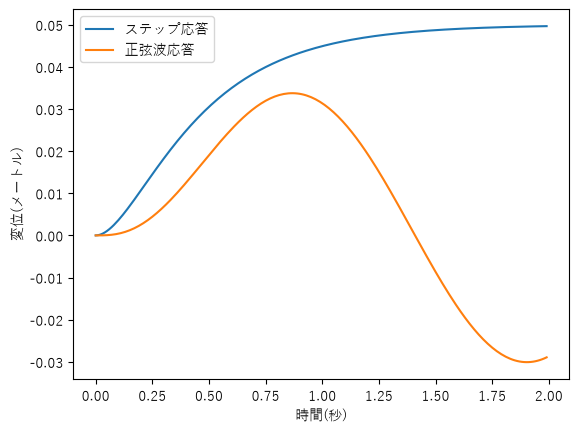

In [5]:
m, b, k = 1.0, 10, 20

numerator = [1]
denominator = [m, b, k]

plant = signal.lti(numerator, denominator)  #❶

t = np.arange(0, 2, 0.01)
_, x_step = plant.step(T=t)  #❷ ステップ応答
_, x_sin, _ = signal.lsim(plant, U=np.sin(np.pi * t), T=t)  #❸ 正弦波応答

plt.plot(t, x_step, label="ステップ応答")
plt.plot(t, x_sin, label="正弦波応答")
plt.legend(loc="best")
plt.xlabel("時間(秒)")
plt.ylabel("変位(メートル)")
plt.show()

図から、ステップ応答が最終的に $x=0.05$ で落ち着くことが分かります。このとき $k x = 1$ です。

伝達関数の四則演算を使うと、複数の系を組み合わせた系を表せます。例えば、2 つの系を直列につないだ伝達関数は、それぞれの伝達関数の積です。伝達関数は多項式の比なので、`numpy.poly1d` の関数で計算できます。

次の `SYS` クラスは、`__mul__`、`__add__`、`__truediv__` などを定義して、伝達関数の四則演算を可能にしたものです。

![フィードバック制御システムのブロック図](images/feedback_system.png)

❶ `feedback()` は、フィードバック系の伝達関数を返します。図で $P$ が制御対象、$C$ がコントローラで、$C$ の入力は目標値と実際の値の差 $x_r - x$ です。$x_r$ から $x$ への伝達関数が、このフィードバック系の伝達関数です。図から、次の式が立ちます。

$$X(s) = (X_r(s) - X(s)) \cdot C(s) \cdot P(s)$$

これを整理すると、次のようになります。

$$\frac{X(s)}{X_r(s)} = \frac{C(s) \cdot P(s)}{1 + C(s) \cdot P(s)}$$

$C(s) \cdot P(s)$ を $Y(s)$ とおくと、フィードバック系の伝達関数は $\frac{Y(s)}{1 + Y(s)}$ です。

❷ `SYS` オブジェクトを `step()` や `lsim()` の第 1 引数に渡せるように、`__iter__()` を定義して、分子と分母の係数を順に返します。

In [6]:
from numbers import Real


def as_sys(s):
    """数値が来たら、定数の伝達関数として扱う。"""
    if isinstance(s, Real):
        return SYS([s], [1])
    return s


class SYS(object):
    def __init__(self, num, den):
        self.num = num
        self.den = den

    def feedback(self):  #❶
        return self / (self + 1)

    def __mul__(self, s):
        s = as_sys(s)
        num = np.polymul(self.num, s.num)
        den = np.polymul(self.den, s.den)
        return SYS(num, den)

    def __add__(self, s):
        s = as_sys(s)
        den = np.polymul(self.den, s.den)
        num = np.polyadd(np.polymul(self.num, s.den), np.polymul(s.num, self.den))
        return SYS(num, den)

    def __radd__(self, s):      # 1 + SYS(...) の形に対応する
        return self + s

    def __truediv__(self, s):
        s = as_sys(s)
        return self * SYS(s.den, s.num)

    def __iter__(self):  #❷
        return iter((self.num, self.den))

次の例では、`SYS` クラスで PI コントローラを作り、質量-ばね-ダンパ系を制御したときのステップ応答を計算します。PI コントローラの伝達関数は次のとおりです。

$$C = \frac{K_p s + K_i}{s} $$

前の章の PI コントローラは離散時間で、積分器をアキュムレータで近似しました。ここでは連続時間の伝達関数で制御系を組み立てます。

❶ 制御対象の伝達関数を `plant` とします。❷ PI コントローラの伝達関数を `pi_ctrl` とします。分母の定数項が 0 だと `step()` が `LinAlgError` になるので、非常に小さい値を入れています。❸ フィードバック系の伝達関数を計算します。

$K_i=0$ だと、出力と目標値の間に一定の差が残ります。$K_p$ を大きくすると差は小さくなりますが、行き過ぎ(オーバーシュート)が出ます。$K_p$ と $K_i$ を調整すれば行き過ぎは減りますが、目標値を少し超える瞬間は残ります。

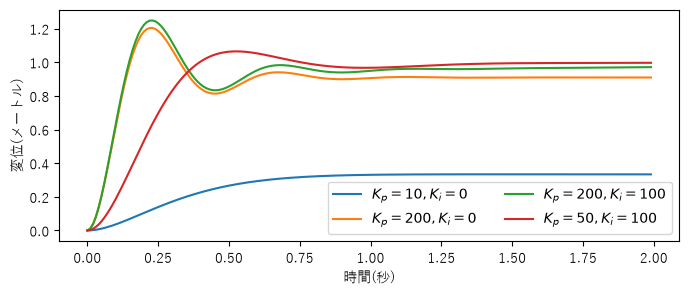

In [7]:
M, b, k = 1.0, 10, 20
plant = SYS([1], [M, b, k])  #❶

pi_settings = [(10, 1e-10), (200, 1e-10), (200, 100), (50, 100)]

fig, ax = plt.subplots(figsize=(8, 3))

for pi_setting in pi_settings:
    pi_ctrl = SYS(pi_setting, [1, 1e-6])  #❷
    feedback = (pi_ctrl * plant).feedback()  #❸
    _, x = signal.step(feedback, T=t)
    label = "$K_p={:d}, K_i={:3.0f}$".format(*pi_setting)
    ax.plot(t, x, label=label)

ax.legend(loc="best", ncol=2)
ax.set_xlabel("時間(秒)")
ax.set_ylabel("変位(メートル)")
plt.show()

質量に加わる力を求めるには、誤差の信号を `lsim()` に渡して、コントローラの出力を計算します。

In [8]:
_, f, _ = signal.lsim(pi_ctrl, U=1 - x, T=t)

行き過ぎを完全に消すには、PID 制御にする必要があります。PID コントローラの伝達関数は次のとおりです。

$$C = \frac{K_d s^2 + K_p s + K_i}{s} $$

次のコードは、PID コントローラで組み立てたフィードバック系のステップ応答を計算します。PID は入力信号を微分するので、ステップ入力に対しては、幅がほぼ 0 で高さが非常に大きいパルスが出力に出ます。

In [9]:
kd, kp, ki = 30, 200, 400
pid_ctrl = SYS([kd, kp, ki], [1, 1e-6])
feedback = (pid_ctrl * plant).feedback()
_, x2 = signal.step(feedback, T=t)

コントローラの出力を現実的な範囲に収めるために、フィードバック系の前にローパスフィルタを入れます。1 次のローパスフィルタの伝達関数は $\frac{1}{a \cdot s + 1}$ です。ローパスフィルタを入れると、PID コントローラへの入力がなめらかになります。

![ローパスフィルタを備えたフィードバック制御システムのブロック図](images/feedback_system_lp.png)

In [10]:
lp = SYS([1], [0.2, 1])
lp_feedback = lp * (pid_ctrl * plant).feedback()
_, x3 = signal.step(lp_feedback, T=t)

PID コントローラの伝達関数は、分子の次数が分母の次数より高いので、`lsim()` で応答を計算できません。そこで、$x_r$ を入力、$f$ を出力として、$x_r$ から $f$ への伝達関数を求めます。次の式から、

$$ F(s) = (X_r(s) \cdot LP(s) - F(s) \cdot P(s)) \cdot C(s)$$

伝達関数は次のようになります。

$$\frac{F(s)}{X_r(s)} = \frac{C(s) \cdot LP(s)}{C(s) \cdot P(s) + 1}$$

この式で、コントローラの出力を計算します。

In [11]:
pid_out = (pid_ctrl * lp) / (pid_ctrl * plant + 1)
_, f3 = signal.step(pid_out, T=t)

最後に、PI 制御、PID 制御、ローパスフィルタ付きの PID 制御について、変位と制御力を並べます。PID 制御の力にはパルスが含まれるので、図には正しく描けません。変位の曲線から、ローパスフィルタが行き過ぎを抑えていることが分かります。

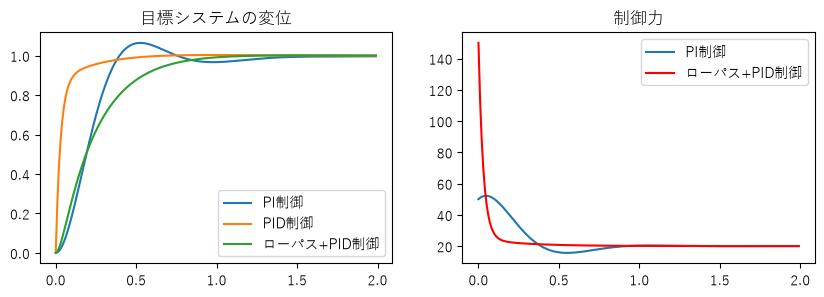

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3))
ax1.plot(t, x, label="PI制御")
ax1.plot(t, x2, label="PID制御")
ax1.plot(t, x3, label="ローパス+PID制御")
ax2.plot(t, f, label="PI制御")
ax2.plot(t, f3, color="r", label="ローパス+PID制御")
ax1.legend(loc="best")
ax2.legend(loc="best")
ax1.set_title("目標システムの変位")
ax2.set_title("制御力")
plt.show()

## まとめ

* メディアンフィルタは `medfilt()`、順序を指定したいときは `order_filter()` を使う。
* IIR フィルタは `iirdesign()` で設計し、`freqz()` で周波数応答を確かめる。
* 周波数スイープ波を `chirp()` で作り、`lfilter()` に通すと、系の周波数特性を測れる。
* 連続時間の系は `lti` で表し、`step()` と `lsim()` で応答を計算する。
* 伝達関数は多項式の比なので、`polymul()` と `polyadd()` で四則演算を組み立てられる。
* フィードバック系の伝達関数は $\frac{Y}{1+Y}$ で、PI 制御の行き過ぎはローパスフィルタ付きの PID で抑えられる。